# Assignment 1: EDA and Baselines

CENG313 Introduction to Data Science (Gazi University), Group 10: Yasin Ünal, Abdullah Kaan Yurtseven, Salih Özçam.
Kaggle competition: [BYU - Locating Bacterial Flagellar Motors 2025](https://www.kaggle.com/competitions/byu-locating-bacterial-flagellar-motors-2025).

**Task.** For each cryo-ET tomogram (a 3D image of a bacterium), decide whether it contains a flagellar motor and, if so, predict the motor centre (z, y, x). Scored with F2; a prediction counts if it is within 1000 Å of a true motor.

**Where the required sections are**

| Required section | In this notebook |
|---|---|
| 1. Problem definition | 2. Problem and metric |
| 2. Data overview | 3. Data description, 3.1 Data overview |
| 3. Exploratory data analysis | 4. Metadata EDA, 5. Motor location EDA, 6. Image EDA, 7. Summary of EDA observations |
| 4. Preprocessing | 1. Data download (downsampling), 8. Preprocessing and evaluation setup |
| 5. Baseline model | 9. Baselines B0 and B1, 10. B2: patch classifier + sliding window |
| 6. Kaggle submission | 11. Summary → Kaggle submissions (screenshot in `submissions/`) |
| 7. Conclusion | 11. Summary → Conclusion and next steps |

All reusable code lives in `src/` (`data.py`, `plots.py`, `utils.py`, `models.py`); this notebook only calls it. The individual working notebooks are in `notebooks/drafts/`.

**Runtime.** "Run all" takes about 15 minutes on a Colab CPU; most of it is training B2 in section 10.2.

## 0. Setup

Clones the repository (public, no token needed) and adds it to the Python path. Run this notebook in Google Colab.

In [1]:
import os, sys

REPO_URL = "https://github.com/ceng313-2026/GROUP10_CENG313.git"   # public repository
REPO_DIR = "/content/GROUP10_CENG313"

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull

sys.path.insert(0, REPO_DIR)
!pip -q install -r {REPO_DIR}/requirements.txt

Cloning into '/content/GROUP10_CENG313'...
remote: Enumerating objects: 174, done.
remote: Counting objects: 100% (174/174), done.
remote: Compressing objects: 100% (113/113), done.
remote: Total 174 (delta 78), reused 125 (delta 43), pack-reused 0 (from 0)
Receiving objects: 100% (174/174), 5.20 MiB | 16.96 MiB/s, done.
Resolving deltas: 100% (78/78), done.


## 1. Data download

Upload your `kaggle.json` (Kaggle -> Settings -> API -> Create New Token) when prompted.

The raw competition data is about 70 GB of JPEG slices, too large for Colab. We downsampled every training tomogram 8x on all axes on Kaggle (`kaggle/downsample_train.py`) and published the result as the public Kaggle Dataset `yasunl/group10-byu-downsampled-8x` (0.35 GB).

After the download, `data/` contains:
- `labels_downsampled.csv`: the competition's training labels plus `z_s, y_s, x_s` (motor coordinates in the small volume = original / 8)
- `downsampled/<tomo_id>.npz`: one small volume per tomogram
- `examples/<tomo_id>.npz`: full-resolution slices around the motor for the image EDA

In [2]:
from google.colab import files
import os

if not os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
    uploaded = files.upload()  # choose kaggle.json
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    !mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

# Skip the download if a previous run in this Colab session already did it.
if not os.path.exists("data/labels_downsampled.csv"):
    !kaggle datasets download -d yasunl/group10-byu-downsampled-8x -p data --unzip
!ls data
!ls data/downsampled | wc -l   # 648 volumes

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/yasunl/group10-byu-downsampled-8x
License(s): unknown
100% 348M/348M [00:17<00:00, 20.5MB/s]

downsampled  examples  labels_downsampled.csv
648


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, utils, models, plots

labels = data.load_labels("data/labels_downsampled.csv")   # one row per motor
tomos = data.tomogram_table(labels)                          # one row per tomogram
print(labels.shape, tomos.shape)
labels.head()

(737, 14) (648, 7)


,row_id,tomo_id,z,y,x,shape_z,shape_y,shape_x,voxel_spacing,n_motors,z_s,y_s,x_s,has_motor
0,0,tomo_003acc,-1.0,-1.0,-1.0,500,1912,1847,6.5,0,-1.000,-1.000,-1.000,False
1,1,tomo_00e047,169.0,546.0,603.0,300,959,928,15.6,1,21.125,68.250,75.375,True
2,2,tomo_00e463,235.0,403.0,137.0,500,924,956,19.7,6,29.375,50.375,17.125,True
3,3,tomo_00e463,243.0,363.0,153.0,500,924,956,19.7,6,30.375,45.375,19.125,True
4,4,tomo_00e463,222.0,379.0,144.0,500,924,956,19.7,6,27.750,47.375,18.000,True


In [4]:
# Sanity check of the downsampled data: every tomogram has a volume, and every
# motor coordinate (original / 8) falls inside its small volume.
from pathlib import Path

npz_files = sorted(Path("data/downsampled").glob("*.npz"))
print(len(npz_files), "volumes for", tomos.shape[0], "tomograms")

volume, meta = data.load_downsampled(npz_files[0])
print(npz_files[0].stem, volume.shape, volume.dtype, meta)

motors = labels[labels.has_motor]
inside = 0
for tomo_id, group in motors.groupby("tomo_id"):
    shape = data.load_downsampled(Path("data/downsampled") / f"{tomo_id}.npz")[0].shape
    inside += ((group[["z_s", "y_s", "x_s"]].to_numpy() < shape).all(axis=1)).sum()
print(f"{inside}/{len(motors)} motor coordinates inside their downsampled volume")

648 volumes for 648 tomograms
tomo_003acc (62, 239, 231) uint8 {'orig_z': 500, 'orig_y': 1912, 'orig_x': 1847, 'voxel_spacing': 6.5, 'factor': 8}
451/451 motor coordinates inside their downsampled volume


## 2. Problem and metric

Each training example is a cryo-electron tomogram, a 3D image of a bacterium. The task is to decide whether the tomogram contains a flagellar motor and, if it does, to predict the motor centre as (z, y, x) voxel coordinates. Predictions are scored with the F2 score: a prediction within 1000 Å of a true motor centre is a hit (TP); a prediction that is too far away, or no prediction, is a missed motor (FN); and a prediction on a tomogram without a motor is a false alarm (FP). With β = 2, recall weighs more than precision, so missing a motor costs more than a false alarm. Because the threshold is in ångströms, distances in voxels must be converted using each tomogram's voxel spacing.

## 3. Data description

- **Instance:** one tomogram (a 3D cryo-ET volume). **Cardinality:** n = 648 training tomograms.
- **Features:** for a model, the voxel intensities of the tomogram (the image itself). The label file adds per-tomogram metadata (shape, voxel spacing) and the targets (motor coordinates).
- **Label file:** `train_labels.csv` has 737 rows, one per motor (tidy data: one observation per row). Tomograms without a motor appear once, with coordinates −1.
- **Data type:** the raw tomograms are stacks of 2D JPEG slices (unstructured image data); the label file is structured tabular data.

| Column | Meaning | Level of measurement | Why |
|---|---|---|---|
| `row_id` | row number | nominal | an identifier; only equal / not equal is meaningful |
| `tomo_id` | tomogram name | nominal | an identifier; only equal / not equal is meaningful |
| `Motor axis 0/1/2` (z, y, x) | motor centre, in voxels | interval | differences (distances) are meaningful, but zero is just the corner of the array, so ratios are not |
| `Array shape (axis 0/1/2)` | tomogram size, in voxels | ratio | a count of voxels with a true zero; 1912 is twice 956 |
| `Voxel spacing` | size of one voxel, in Å | ratio | a physical length with a true zero; 19.7 Å is about 3× 6.5 Å |
| `Number of motors` | motors in the tomogram | ratio (discrete) | a count with a true zero |
| `has_motor` (derived) | motor present or not | asymmetric binary | "motor present" is the outcome that matters; the F2 metric penalises a missed motor more than a false alarm |

- **Sentinel values:** a coordinate of −1 means "no motor", not a real position. These rows must be excluded (using `has_motor`) before computing statistics on motor positions; otherwise, for example, the mean position is pulled towards −1.

In [5]:
print("label rows (one per motor):", len(labels))
print("tomograms:", len(tomos))
tomos.head()

label rows (one per motor): 737
tomograms: 648


,tomo_id,shape_z,shape_y,shape_x,voxel_spacing,n_motors,has_motor
0,tomo_003acc,500,1912,1847,6.5,0,False
1,tomo_00e047,300,959,928,15.6,1,True
2,tomo_00e463,500,924,956,19.7,6,True
3,tomo_01a877,300,960,928,13.1,1,True
4,tomo_02862f,300,959,928,15.6,1,True


### 3.1 Data overview: types, summary statistics, missing values, duplicates

The label table is the tabular part of the data (the tomograms themselves are images, described in sections 1 and 6). `labels` is `labels_downsampled.csv`: the competition's `train_labels.csv` plus `z_s, y_s, x_s` (motor position in the 8x downsampled volume) and the derived `has_motor`.

In [6]:
print("shape:", labels.shape)
print(labels.dtypes)
labels.describe().T.round(2)

shape: (737, 14)
row_id             int64
tomo_id           object
z                float64
y                float64
x                float64
shape_z            int64
shape_y            int64
shape_x            int64
voxel_spacing    float64
n_motors           int64
z_s              float64
y_s              float64
x_s              float64
has_motor           bool
dtype: object


,count,mean,std,min,25%,50%,75%,max
row_id,737.0,368.00,212.90,0.0,184.0,368.00,552.00,736.00
z,737.0,101.86,102.21,-1.0,-1.0,106.00,170.00,466.00
y,737.0,294.85,282.33,-1.0,-1.0,278.00,549.00,904.00
x,737.0,300.82,293.37,-1.0,-1.0,280.00,567.00,902.00
shape_z,737.0,422.65,174.34,300.0,300.0,300.00,500.00,800.00
shape_y,737.0,950.21,64.86,924.0,928.0,959.00,960.00,1912.00
shape_x,737.0,954.82,97.23,924.0,928.0,928.00,956.00,1847.00
voxel_spacing,737.0,15.34,2.40,6.5,13.1,15.60,16.80,19.70
n_motors,737.0,1.13,1.64,0.0,0.0,1.00,1.00,10.00
z_s,737.0,12.39,13.12,-1.0,-1.0,13.25,21.25,58.25


In [7]:
print("missing values (NaN) in the whole table:", int(labels.isna().sum().sum()))
print("rows with the -1 'no motor' value:", int((~labels.has_motor).sum()))
print("exact duplicate rows (ignoring row_id):", int(labels.drop(columns="row_id", errors="ignore").duplicated().sum()))
print("rows whose tomo_id appeared before (extra motors in the same tomogram):", int(labels.tomo_id.duplicated().sum()))
print("tomograms with more than one motor:", int((tomos.n_motors > 1).sum()))
print("'Number of motors' summed over tomograms:", int(tomos.n_motors.sum()),
      "| labelled motor coordinates:", int(labels.has_motor.sum()))

missing values (NaN) in the whole table: 0
rows with the -1 'no motor' value: 286
exact duplicate rows (ignoring row_id): 0
rows whose tomo_id appeared before (extra motors in the same tomogram): 89
tomograms with more than one motor: 49
'Number of motors' summed over tomograms: 455 | labelled motor coordinates: 451


**Observation:**
- **Types:** all columns are numeric except `tomo_id` (text identifier) and `has_motor` (boolean). The motor coordinates are stored as decimals (`float64`) in the label file; `z_s, y_s, x_s` are the same coordinates divided by 8.
- **Summary statistics:** the minimum of every coordinate column is −1. This is not a real position but the "no motor" value, so `describe()` on the raw columns is misleading for positions; position statistics are computed on motors only (section 5).
- **Missing values:** there are no NaN values. Missing information is encoded instead: "no motor" as −1 (the 286 tomograms without a motor), and 4 motors are counted in `Number of motors` but have no coordinates (455 counted vs 451 labelled).
- **Duplicates:** no row is an exact copy of another. A `tomo_id` repeats only when a tomogram has several motors (one row per motor, tidy data), so these rows are kept. Per-tomogram views use `tomos`, which has one row per tomogram.

## 4. Metadata EDA

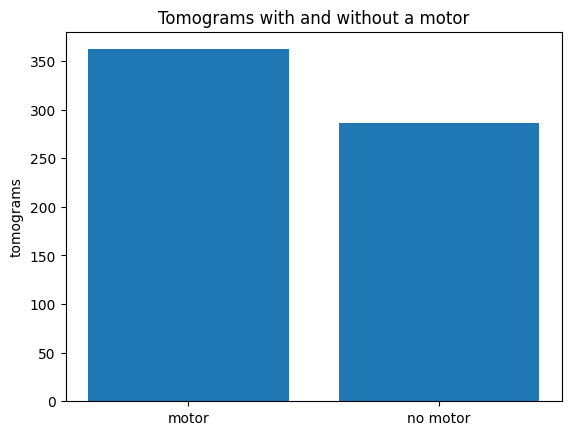

In [8]:
plots.class_balance(tomos)
plt.show()

In [9]:
tomos["has_motor"].value_counts()

,count
has_motor,
True,362
False,286


**Observation:** 362 of the 648 training tomograms (56%) contain at least one motor and 286 (44%) contain none, so the two classes are fairly balanced.

In [10]:
tomos["n_motors"].value_counts().sort_index()

,count
n_motors,
0,286
1,313
2,30
3,6
4,9
6,3
10,1


In [11]:
print("n_motors column sums to:", tomos["n_motors"].sum())
print("Motors with coordinates:", labels["has_motor"].sum())

n_motors column sums to: 455
Motors with coordinates: 451


**Observation:** Most tomograms with a motor contain exactly one: 313 of 362 (86%). The other 49 contain between 2 and 10 motors. Since a submission has only one predicted point per tomogram, a model only needs to find one of the motors in these tomograms (this is how our F2 function in `src/utils.py` scores them). The `n_motors` column sums to 455, but the CSV has coordinates for only 451 motors, so 4 motors are counted but not labelled.

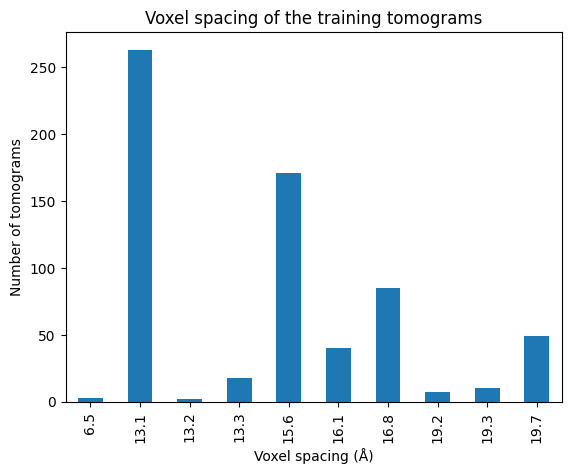

In [12]:
import matplotlib.pyplot as plt

from src import plots

plots.voxel_spacing(tomos)
plt.show()

In [13]:
tomos["voxel_spacing"].value_counts().sort_index()

,count
voxel_spacing,
6.5,3
13.1,263
13.2,2
13.3,18
15.6,171
16.1,40
16.8,85
19.2,7
19.3,10


**Observation:** Voxel spacing takes only 10 distinct values, from 6.5 Å to 19.7 Å; most tomograms use 13.1 Å (263) or 15.6 Å (171). Because the spacing differs between tomograms, the 1000 Å threshold corresponds to about 154 voxels in the finest tomograms but only about 51 voxels in the coarsest ones, so distances must be compared in ångströms, not in voxels.

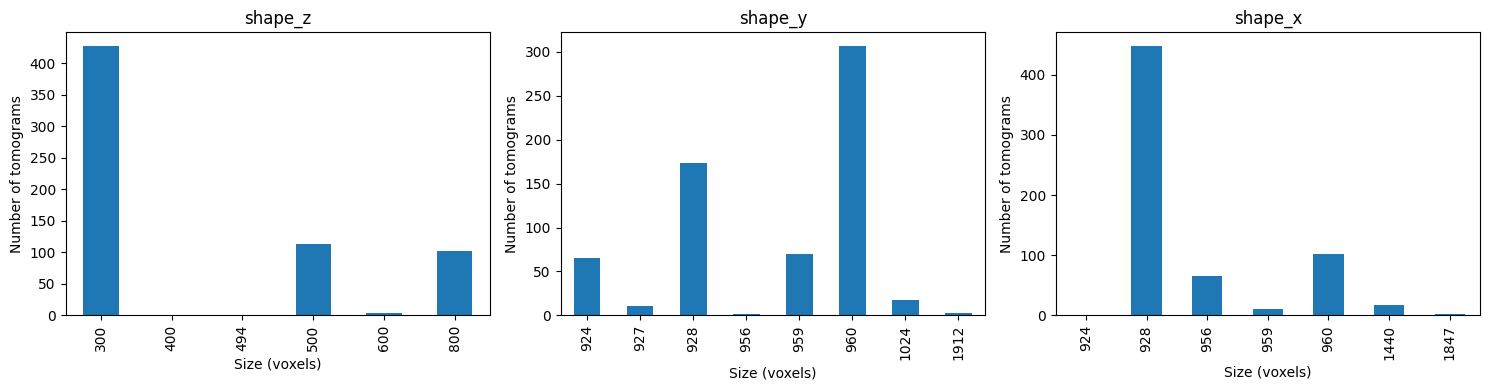

In [14]:
plots.tomogram_sizes(tomos)
plt.show()

In [15]:
for col in ["shape_z", "shape_y", "shape_x"]:
    print(tomos[col].value_counts().sort_index(), "\n")

shape_z
300    428
400      1
494      1
500    113
600      3
800    102
Name: count, dtype: int64 

shape_y
924      65
927      11
928     173
956       1
959      70
960     307
1024     18
1912      3
Name: count, dtype: int64 

shape_x
924       1
928     448
956      65
959      11
960     102
1440     18
1847      3
Name: count, dtype: int64 



In [16]:
tomos[tomos["shape_y"] == 1912]

,tomo_id,shape_z,shape_y,shape_x,voxel_spacing,n_motors,has_motor
0,tomo_003acc,500,1912,1847,6.5,0,False
504,tomo_c77de0,494,1912,1847,6.5,0,False
639,tomo_fc90fd,500,1912,1847,6.5,0,False


**Observation:** Tomograms do not share a single size. Along z most have 300 slices (428), the rest mostly 500 (113) or 800 (102); in y and x most are 924–960 voxels, with two groups of outliers: 1024 × 1440 (18 tomograms) and 1912 × 1847 (3). The 3 largest are exactly the tomograms with the smallest voxel spacing (6.5 Å), so in physical size (≈12,400 Å) they match the others: a larger array means a finer resolution, not a larger sample. None of these 3 contains a motor, so the training set has no positive example at this resolution. Since sizes differ, a model needs fixed-size inputs (resizing or patches), and motor positions should be compared after normalising by tomogram size or converting to Å.

## 5. Motor location EDA

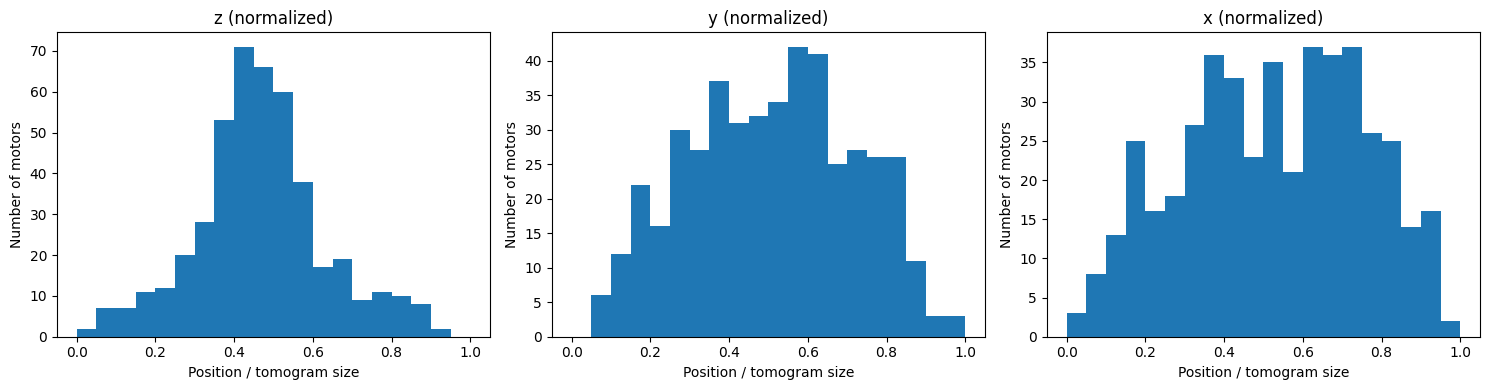

In [17]:
plots.position_histograms(labels)
plt.show()

In [18]:
motors = plots.normalized_positions(labels)
cols = ["z_norm", "y_norm", "x_norm"]

print(motors[cols].describe().round(2))
print("Motors within 5% of an edge:")
print(((motors[cols] < 0.05) | (motors[cols] > 0.95)).sum())

       z_norm  y_norm  x_norm
count  451.00  451.00  451.00
mean     0.47    0.51    0.53
std      0.16    0.21    0.23
min      0.00    0.06    0.03
25%      0.37    0.35    0.36
50%      0.46    0.51    0.53
75%      0.55    0.67    0.71
max      0.93    0.97    0.97
Motors within 5% of an edge:
z_norm    2
y_norm    3
x_norm    5
dtype: int64


**Observation:** Along z, motors cluster around the middle of the volume: half of them lie between 0.37 and 0.55 of the tomogram depth. Along y and x they are spread much more widely (the middle half covers 0.35–0.67 in y and 0.36–0.71 in x), so in the top view a motor can be almost anywhere. Very few motors lie within 5% of an edge (2 in z, 3 in y, 5 in x). B1 predicts the mean position (0.47, 0.51, 0.53) for every tomogram; the wide spread in y and x already suggests that this single point will usually be far from the true motor.

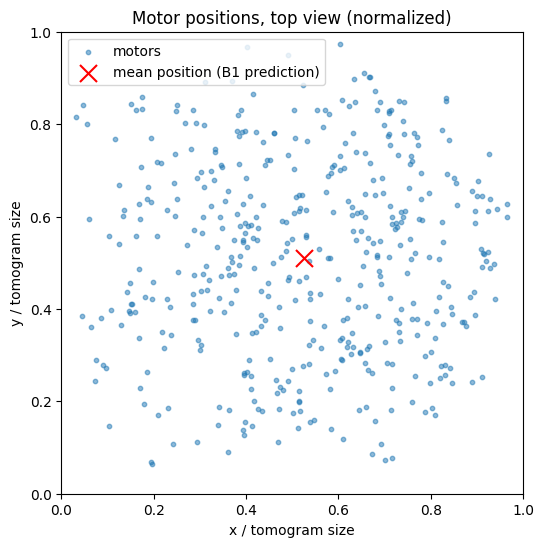

In [19]:
plt.figure(figsize=(6, 6))
plots.position_yx(labels)
plt.show()

In [20]:
corner = ((motors["x_norm"] < 0.15) | (motors["x_norm"] > 0.85)) & \
         ((motors["y_norm"] < 0.15) | (motors["y_norm"] > 0.85))
print("Motors in the four corners (outer 15% in both x and y):", corner.sum(), "of", len(motors))

Motors in the four corners (outer 15% in both x and y): 1 of 451


**Observation:** In the top view the motors are spread over most of the tomogram rather than concentrated around B1's prediction (red cross), which sits in the middle of a wide cloud. The corners are almost empty: the four corner regions (outer 15% in both x and y) cover 9% of the area but contain only 1 of the 451 motors, so the motors form a roughly round cloud around the centre. A single fixed point therefore cannot be close to most motors; the next plot measures how far it actually is.

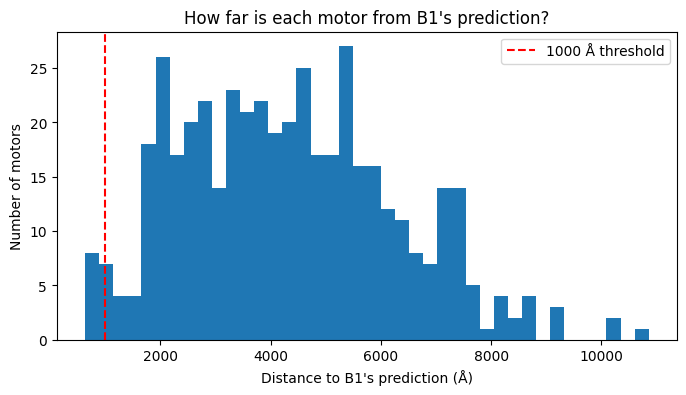

In [21]:
plt.figure(figsize=(8, 4))
plots.distance_to_mean_hist(labels)
plt.show()

In [22]:
dist = plots.distances_to_mean(labels)
print(dist.describe().round(0))
print("Motors within 1000 Å of B1's prediction:", (dist <= 1000).sum(), "of", len(dist))

motors["dist"] = dist
closest = motors.groupby("tomo_id")["dist"].min()   # per tomogram: the motor closest to B1's guess
print("Tomograms where B1 hits a motor:", (closest <= 1000).sum(), "of", len(closest))

count      451.0
mean      4329.0
std       1940.0
min        633.0
25%       2769.0
50%       4248.0
75%       5588.0
max      10857.0
dtype: float64
Motors within 1000 Å of B1's prediction: 9 of 451
Tomograms where B1 hits a motor: 8 of 362


**Observation:** This plot explains B1's score. The median distance from a motor to B1's prediction is about 4,250 Å, more than four times the 1000 Å threshold, and only 9 of the 451 motors (2%) fall within it. Counted per tomogram, as the metric does, B1 hits a motor in only 8 of the 362 tomograms that contain one (2.2%), and it raises a false alarm on every one of the 286 tomograms without a motor. This matches its very low Kaggle score (public 0.0104, see the README). A useful model has to locate each motor; guessing a typical position is not enough.

## 6. Image EDA

16 example tomograms, 12 with a motor
1000 Å in tomo_00e047 = 64 voxels


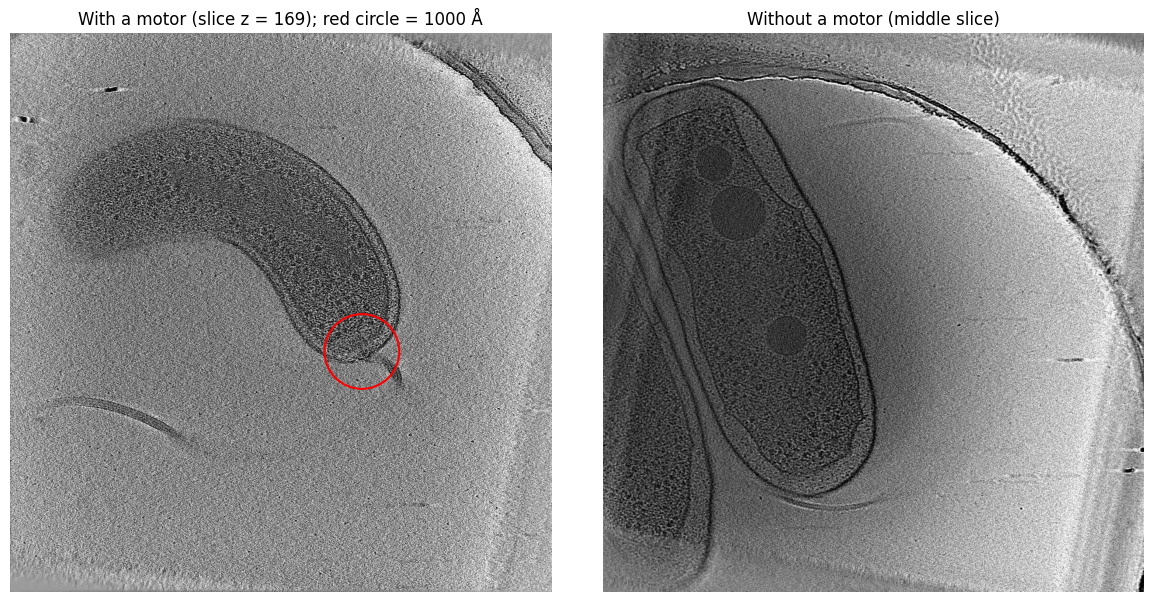

In [23]:
examples = plots.load_examples("data/examples")
spacing = tomos.set_index("tomo_id")["voxel_spacing"]
print(len(examples), "example tomograms,", sum("crops" in e for e in examples.values()), "with a motor")
print("1000 Å in tomo_00e047 =", round(1000 / spacing["tomo_00e047"]), "voxels")

plots.motor_vs_no_motor(examples["tomo_00e047"], examples["tomo_0308c5"], spacing["tomo_00e047"])
plt.show()

**Observation:** In tomo_00e047 the motor is a small structure at the end of the bacterium, where the flagellum (the thin "tail") leaves the cell. The red circle marks the 1000 Å threshold, only 64 voxels in this tomogram and much smaller than the bacterium, so a prediction has to land on the right end of the right cell. The slice without a motor (tomo_0308c5, same voxel spacing) also shows bacteria but no tail. One slice is not enough to rule out a motor, though, because a motor can lie in a different z slice, so a model has to search the whole 3D volume.

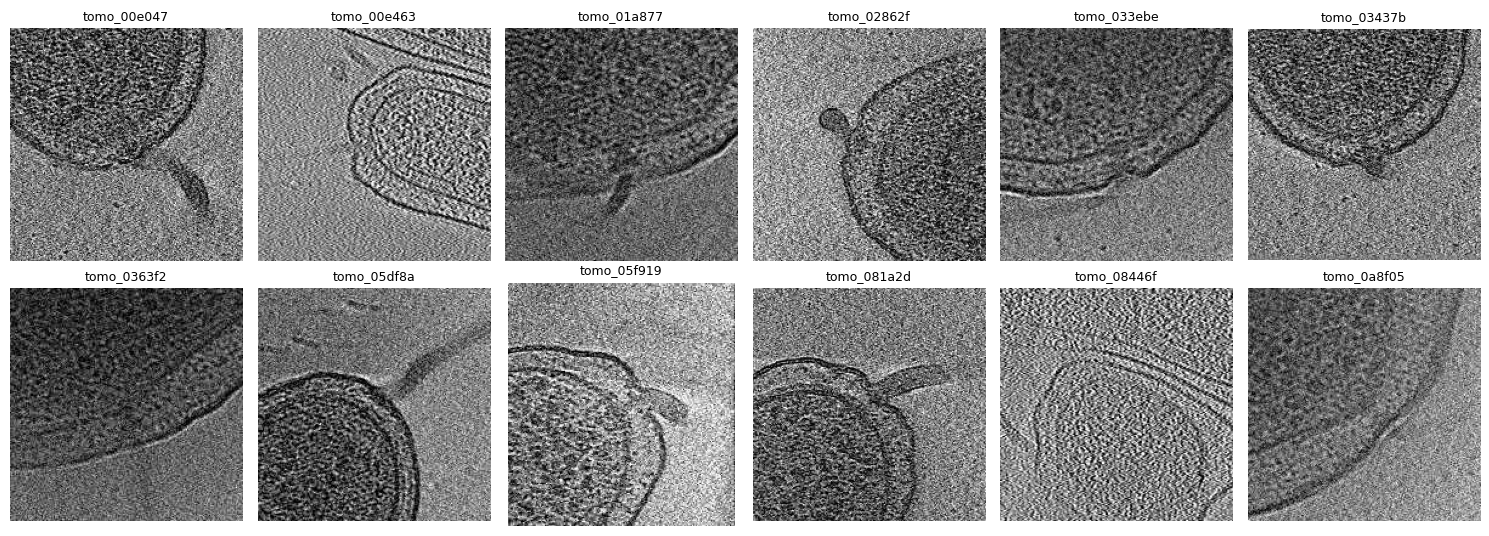

In [24]:
plots.crop_grid(examples)
plt.show()

**Observation:** The motors do not look alike. By eye, the motor is easy to spot in about 7 of the 12 crops (e.g. tomo_00e047, tomo_02862f, tomo_05df8a): it sits in the cell envelope at the base of the flagellum, the thin tail that leaves the cell. In the other 5 (tomo_00e463, tomo_033ebe, tomo_0363f2, tomo_08446f, tomo_0a8f05) it is small, faint or its tail is not in this slice. Contrast and noise also differ between tomograms. A detector cannot rely on one fixed template; it has to learn from many examples and should use neighbouring slices (3D context), not a single slice.

Downsampled volume: (37, 120, 116) | original: (300, 959, 928)
1000 Å in the downsampled volume = 8.0 voxels


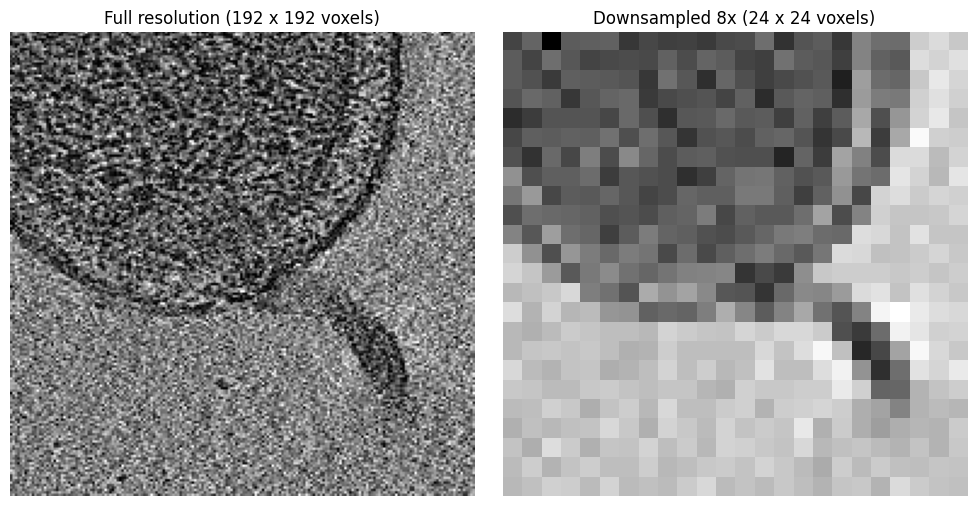

In [25]:
vol, meta = data.load_downsampled("data/downsampled/tomo_00e047.npz")
print("Downsampled volume:", vol.shape, "| original:", (meta["orig_z"], meta["orig_y"], meta["orig_x"]))
print("1000 Å in the downsampled volume =", round(1000 / (meta["voxel_spacing"] * meta["factor"]), 1), "voxels")

plots.full_vs_downsampled(examples["tomo_00e047"], vol, factor=meta["factor"])
plt.show()

**Observation:** After 8x downsampling, the same area shrinks from 192 × 192 to 24 × 24 voxels. The cell edge and the flagellum are still visible (the tail becomes a short dark streak of a few voxels), but the motor itself merges into the cell envelope and is no longer a separate structure. Knowing where to look makes it easy to spot; finding it without a hint in the whole 37 × 120 × 116 volume is much harder. Since 1000 Å is still 8 voxels at this scale, 8x is fine-grained enough for the metric, and the base of the tail at the cell edge is the main visual cue a model can use. Finer detail would need less downsampling or full-resolution patches around candidate locations.    

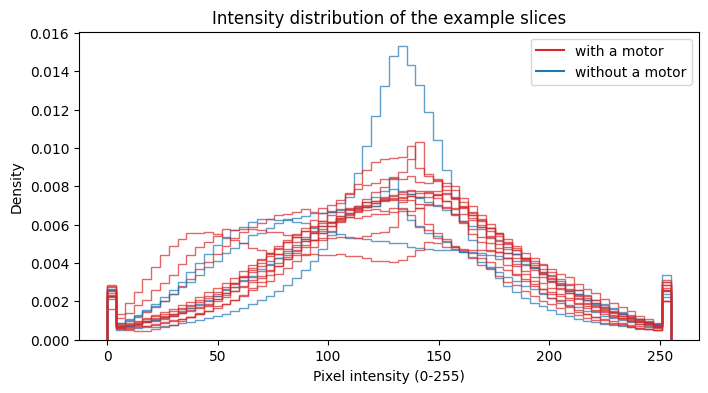

In [26]:
plt.figure(figsize=(8, 4))
plots.intensity_histograms(examples)
plt.show()

In [27]:
for name, e in examples.items():
    image = e["motor_slice"] if "crops" in e else e["middle_slice"]
    print(name, "motor   " if "crops" in e else "no motor", "mean", round(image.mean()), "std", round(image.std()))

tomo_003acc no motor mean 131 std 43
tomo_00e047 motor    mean 134 std 53
tomo_00e463 motor    mean 130 std 48
tomo_01a877 motor    mean 113 std 53
tomo_02862f motor    mean 132 std 54
tomo_0308c5 no motor mean 119 std 60
tomo_0333fa no motor mean 116 std 55
tomo_033ebe motor    mean 114 std 59
tomo_03437b motor    mean 134 std 53
tomo_0363f2 motor    mean 118 std 65
tomo_040b80 no motor mean 132 std 54
tomo_05df8a motor    mean 125 std 50
tomo_05f919 motor    mean 126 std 53
tomo_081a2d motor    mean 129 std 54
tomo_08446f motor    mean 136 std 50
tomo_0a8f05 motor    mean 134 std 52


**Observation:** Each line is the brightness distribution of one example slice. All slices look alike: most pixels are mid-grey, and the means overlap completely (113–136 with a motor, 116–132 without; standard deviations 43–65). The spikes at 0 and 255 come from the competition's preprocessing, which clipped each slice at its 1st and 99th percentiles before scaling it to 0–255. The single narrow blue peak is tomo_003acc, the only 6.5 Å tomogram here. Overall brightness therefore says nothing about whether a motor is present, since the motor covers only a tiny part of the slice; a model has to use local shape (the motor and tail at the cell edge), not global intensity.

## 7. Summary of EDA observations

1. **Labels:** 648 training tomograms, 362 with a motor (56%) and 286 without, so the classes are fairly balanced. Most motor tomograms contain one motor (313 of 362); `n_motors` counts 4 motors that have no coordinates.
2. **Scale differs between tomograms:** voxel spacing ranges from 6.5 to 19.7 Å and sizes from 300 to 800 slices (up to 1912 × 1847 in y and x). The 1000 Å threshold is 51–154 voxels, so distances must be measured in Å, and a model needs resized inputs or fixed-size patches. The 3 finest-resolution tomograms (6.5 Å) contain no motor.
3. **Location cannot be guessed:** motors cluster around the middle in z but are spread over most of the y–x plane. A fixed guess (B1) is within 1000 Å of only 9 of 451 motors (median distance ≈ 4,250 Å), which explains its F2 of about 0.01. → In Assignment 2 the model must find the motor from the image content.
4. **What a motor looks like:** a small structure in the cell envelope at the base of the flagellum. Its appearance varies (by eye, clear in about 7 of 12 examples), a single slice may miss it, and overall brightness does not separate slices with and without a motor. → A detector should learn local shape from many examples and use neighbouring slices (3D context).
5. **Resolution:** after 8x downsampling the cell edge and the tail are still visible and 1000 Å is still 8 voxels, so 8x is fine enough for a first detector (B2). → Finer detail, if needed, can come from less downsampling or full-resolution patches around candidate locations.

## 8. Preprocessing and evaluation setup

### Preprocessing decisions

All preparation steps, where they happen and why:

| Step | What we did | Why |
|---|---|---|
| Size reduction | Every tomogram shrunk 8x on all three axes by block averaging (section 1, `kaggle/downsample_train.py`, `src/data.py`) | The raw data is about 70 GB and does not fit in Colab (0.35 GB after). Averaging instead of skipping slices reduces noise. The same factor on every axis keeps voxels cubic, so positions convert by dividing by 8. Section 6 shows the cell edge and flagellum are still visible and 1000 Å is still about 8 voxels |
| Intensity scaling | The organizers already clipped each slice to its 1st–99th percentile and scaled it to 0–255. For B2 each volume is additionally standardized to mean 0, std 1 (`models.normalize_volume`); B2-LR also standardizes its patch features (`StandardScaler`) | Brightness and contrast differ between tomograms (section 6), and a patch classifier should react to shape, not to how bright a tomogram is. Logistic regression is sensitive to feature scale |
| Missing values | No imputation. "No motor" (−1) becomes the `has_motor` flag, and −1 rows are left out of position statistics. The 4 counted but unlabelled motors are kept as they are | −1 means "there is no motor", not "unknown", so filling it in would invent motors. Unlabelled motors cannot be used as targets, and their tomograms already have a labelled motor |
| Duplicates | None removed | Repeated `tomo_id` rows are different motors in the same tomogram (3.1) |
| Encoding | None needed | There are no categorical features; `tomo_id` is only an identifier and is never used as a feature |
| Coordinates | B1 uses positions divided by the tomogram size; distances for the metric are converted to Å with each tomogram's voxel spacing | Tomograms have different sizes (300–800 × 924–1912 voxels) and voxel spacings (6.5–19.7 Å) |
| Outliers | Nothing removed | The largest tomograms (1912 × 1847 voxels) are not outliers: their voxels are smaller (6.5 Å), so their physical size matches the others (section 4) |
| Train / validation split | 80 / 20 at tomogram level, stratified by `has_motor`, seed 42 (8.2) | Keeps the motor / no-motor ratio and keeps all motors of one tomogram on the same side (no leakage) |

The next cell shows the per-volume standardization used by B2 on three tomograms.

In [28]:
# per-volume standardization used by B2 (models.normalize_volume)
for tomo_id in tomos.tomo_id[:3]:
    vol, meta = data.load_downsampled(f"data/downsampled/{tomo_id}.npz")
    z = models.normalize_volume(vol)
    print(f"{tomo_id}: raw mean {vol.mean():6.1f}, std {vol.std():5.1f}  ->  "
          f"standardized mean {z.mean():5.2f}, std {z.std():4.2f}")

tomo_003acc: raw mean  131.5, std   4.2  ->  standardized mean -0.00, std 1.00
tomo_00e047: raw mean  130.1, std  27.0  ->  standardized mean  0.00, std 1.00
tomo_00e463: raw mean  128.8, std   7.9  ->  standardized mean -0.00, std 1.00


### 8.1 Metric check

`utils.score` works like the competition metric. A prediction is a TP if it is closer
than 1000 Å to a true motor. If the prediction is too far, or we say "no motor" when there
is a motor, it is a FN. If we predict a motor in a tomogram without a motor, it is a FP.
Then we compute F2.

`tests/test_utils.py` checks `score` on a small example. I also calculated this example by hand:
TP = 2, FP = 1, FN = 2, so precision = 2/3, recall = 1/2 and F2 = 10/19 ≈ 0.526.
The test gives the same numbers.

In [29]:
!cd {REPO_DIR} && python tests/test_utils.py

0.5263157894736842 {'tp': 2, 'fp': 1, 'fn': 2}
OK


### 8.2 Validation split

We split by tomogram, so one tomogram is never in both train and validation (no leakage).
The split is stratified by `has_motor`, so both parts have the same rate of motors.
The seed is fixed, so we get the same split every time.

In [30]:
train_ids, val_ids = utils.split_tomograms(tomos)   # val_size=0.2, seed=42

print("train:", len(train_ids), " val:", len(val_ids))
print("shared tomograms:", len(set(train_ids) & set(val_ids)))   # must be 0

train_rate = tomos[tomos.tomo_id.isin(train_ids)].has_motor.mean()
val_rate = tomos[tomos.tomo_id.isin(val_ids)].has_motor.mean()
print(f"positive rate  train: {train_rate:.1%}   val: {val_rate:.1%}")

train: 518  val: 130
shared tomograms: 0
positive rate  train: 55.8%   val: 56.2%


In [31]:
# with the same seed we get the same split
a, _ = utils.split_tomograms(tomos)
b, _ = utils.split_tomograms(tomos)
c, _ = utils.split_tomograms(tomos, seed=7)
print("same seed, same split:     ", a == b)   # True
print("different seed, same split:", a == c)   # False

same seed, same split:      True
different seed, same split: False


The split was saved once in `splits/val_ids.csv`, so every model (B0, B1, B2 and our Assignment 2 model) is tested on the same 130 tomograms, even if the code or a library changes later. The next cell checks that the saved file is the split computed above; all models below read the split from the file.

In [32]:
saved_val_ids = pd.read_csv(f"{REPO_DIR}/splits/val_ids.csv")["tomo_id"].tolist()
print("saved split == computed split:", sorted(saved_val_ids) == sorted(val_ids))

saved split == computed split: True


## 9. Baselines B0 and B1

B0 always says "no motor". B1 always puts a motor at the average position of the train motors
(position divided by the tomogram size, then multiplied by the size of the new tomogram).
Both use the 518 train tomograms and are scored on the 130 validation tomograms
(ids from `splits/val_ids.csv`).

In [33]:
# use the saved validation ids
val_ids = pd.read_csv(f"{REPO_DIR}/splits/val_ids.csv")["tomo_id"].tolist()
train_ids = [t for t in tomos.tomo_id if t not in set(val_ids)]

train_labels = labels[labels.tomo_id.isin(train_ids)]
val_labels = labels[labels.tomo_id.isin(val_ids)]
val_tomos = tomos[tomos.tomo_id.isin(val_ids)]

results = {}
for name, model in [("B0", models.NoMotorBaseline()), ("B1", models.MeanPositionBaseline())]:
    preds = model.fit(train_labels).predict(val_tomos)
    f2, counts = utils.score(val_labels, preds, return_counts=True)
    p = counts["tp"] / (counts["tp"] + counts["fp"]) if counts["tp"] + counts["fp"] else 0.0
    r = counts["tp"] / (counts["tp"] + counts["fn"]) if counts["tp"] + counts["fn"] else 0.0
    results[name] = {"precision": round(p, 4), "recall": round(r, 4), "F2": round(f2, 4), **counts}

results_df = pd.DataFrame(results).T
results_df

,precision,recall,F2,tp,fp,fn
B0,0.00,0.0000,0.0000,0.0,0.0,73.0
B1,0.05,0.0411,0.0426,3.0,57.0,70.0


**Observations (B0, B1)**
- B0 says "no motor" everywhere, so it misses all 73 motors and F2 = 0. This is the lowest possible score.
- B1 puts a motor in every tomogram. All 57 tomograms without a motor become FP, and only 3 of the
  73 motors are closer than 1000 Å to the average position (F2 = 0.043).
  Motors are in many different places, so one fixed position does not work.
- So a useful model must look at the image. This is the idea of B2.

## 10. B2: patch classifier + sliding window

B2 uses the downsampled tomograms. A classifier looks at small 16x16 2D patches and says
"motor" or "no motor". Then we slide a window over the whole tomogram and take the place with
the highest motor probability. We try two classifiers: Logistic Regression (LR) and Random Forest (RF).
The code is in `src/models.py` (`PatchClassifierBaseline`).

**10.1 Downsampled data.** One file has the small volume and some info (original size,
voxel spacing, factor 8). To go back to original voxels: small coordinate x 8 + 4 (center of the 8x8x8 block).

In [34]:
ds = pd.read_csv("data/labels_downsampled.csv")
print("columns:", ds.columns.tolist())
display(ds.head())

tid = "tomo_003acc"   # one example (this tomogram has no motor)
vol, meta = data.load_downsampled(f"data/downsampled/{tid}.npz")
print("shape:", vol.shape, " dtype:", vol.dtype, " min/max:", vol.min(), vol.max())
print("meta:", meta)
print(ds[ds.tomo_id == tid])

columns: ['row_id', 'tomo_id', 'Motor axis 0', 'Motor axis 1', 'Motor axis 2', 'Array shape (axis 0)', 'Array shape (axis 1)', 'Array shape (axis 2)', 'Voxel spacing', 'Number of motors', 'z_s', 'y_s', 'x_s']


,row_id,tomo_id,Motor axis 0,Motor axis 1,Motor axis 2,Array shape (axis 0),Array shape (axis 1),Array shape (axis 2),Voxel spacing,Number of motors,z_s,y_s,x_s
0,0,tomo_003acc,-1.0,-1.0,-1.0,500,1912,1847,6.5,0,-1.000,-1.000,-1.000
1,1,tomo_00e047,169.0,546.0,603.0,300,959,928,15.6,1,21.125,68.250,75.375
2,2,tomo_00e463,235.0,403.0,137.0,500,924,956,19.7,6,29.375,50.375,17.125
3,3,tomo_00e463,243.0,363.0,153.0,500,924,956,19.7,6,30.375,45.375,19.125
4,4,tomo_00e463,222.0,379.0,144.0,500,924,956,19.7,6,27.750,47.375,18.000


shape: (62, 239, 231)  dtype: uint8  min/max: 10 190
meta: {'orig_z': 500, 'orig_y': 1912, 'orig_x': 1847, 'voxel_spacing': 6.5, 'factor': 8}
   row_id      tomo_id  Motor axis 0  Motor axis 1  Motor axis 2  \
0       0  tomo_003acc          -1.0          -1.0          -1.0   

   Array shape (axis 0)  Array shape (axis 1)  Array shape (axis 2)  \
0                   500                  1912                  1847   

   Voxel spacing  Number of motors  z_s  y_s  x_s  
0            6.5                 0 -1.0 -1.0 -1.0  


**10.2 Training.** Positive patches come from the motors in the train tomograms. We also take the
slice above and below and move the patch 1 pixel, to get more motor examples.
Negative patches are random places more than 2000 Å away from all motors.
We use `class_weight="balanced"` because we have about 3 to 4 times more negatives than positives.

**Why v2?** Our first version (v1) had only random negatives, it searched the whole volume and it
did not smooth the probabilities. On validation it was very bad: LR F2 = 0.000 (0 TP) and RF F2 = 0.017 (1 TP).
The patch classifier itself was good (patch AUC 0.93 for LR and 0.96 for RF), but the search found
the wrong places: 63% (LR) and 47% (RF) of the predictions were near the border, and the median
distance to the motor was 7150 Å (LR) and 5674 Å (RF). One tomogram has about 100,000 windows,
so some strange background places (border, bright spots) get a higher score than the motor.
So in v2 we added:
- hard negatives: we run the first model on the train tomograms, take the wrong "motor" places
  and train again with them as negatives (only train tomograms, not validation),
- margin: we do not search the outer 10% of each axis,
- smoothing: we average each window with its neighbours (3x3x3).

In [35]:
# Block 10.2: train B2 with LR and RF (v2 settings)
import glob, importlib, time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
importlib.reload(models)

VOL_DIR = "data/downsampled"   # downloaded in section 1
print(len(glob.glob(f"{VOL_DIR}/*.npz")), "downsampled volumes")

# v2: 1 round of hard negatives (10 per tomogram), 10% border margin, 3x3x3 smoothing.
# refine is off here, we test it in 10.5
B2_SETTINGS = dict(hard_rounds=1, hard_per_tomo=10, margin=0.1, smooth=3, refine=False)

b2_models = {
    "B2-LR": models.PatchClassifierBaseline(
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
        VOL_DIR, **B2_SETTINGS),
    "B2-RF": models.PatchClassifierBaseline(
        RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=0),
        VOL_DIR, **B2_SETTINGS),
}
for name, m in b2_models.items():
    t = time.time()
    m.fit(train_labels)
    print(f"{name}: {m.n_pos_} positive / {m.n_neg_} negative patches "
          f"({m.n_hard_} hard negatives), {time.time() - t:.0f}s")

648 downsampled volumes
B2-LR: 5311 positive / 20713 negative patches (5173 hard negatives), 34s
B2-RF: 5311 positive / 20467 negative patches (4927 hard negatives), 337s


**10.3 Validation.** We run the sliding window on the 130 validation tomograms one time,
then we try some thresholds. If the probability is lower than the threshold, we say "no motor".

In [36]:
# Block 10.3: predict the validation tomograms, then try some thresholds
b2_preds = {}
for name, m in b2_models.items():
    t = time.time()
    b2_preds[name] = m.predict(val_tomos)
    print(f"{name}: predicted {len(val_tomos)} tomograms in {time.time() - t:.0f}s")

rows = []
for name, p in b2_preds.items():
    for th in [0.0, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95]:
        f2, c = utils.score(val_labels, models.with_threshold(p, th), return_counts=True)
        prec = c["tp"] / (c["tp"] + c["fp"]) if c["tp"] + c["fp"] else 0.0
        rec = c["tp"] / (c["tp"] + c["fn"]) if c["tp"] + c["fn"] else 0.0
        rows.append({"model": name, "threshold": th, "F2": round(f2, 4), **c,
                     "precision": round(prec, 3), "recall": round(rec, 3)})
b2_results = pd.DataFrame(rows)
b2_results

B2-LR: predicted 130 tomograms in 6s
B2-RF: predicted 130 tomograms in 55s


,model,threshold,F2,tp,fp,fn,precision,recall
0,B2-LR,0.00,0.0426,3,57,70,0.050,0.041
1,B2-LR,0.30,0.0426,3,57,70,0.050,0.041
2,B2-LR,0.50,0.0426,3,57,70,0.050,0.041
3,B2-LR,0.70,0.0000,0,31,73,0.000,0.000
4,B2-LR,0.80,0.0000,0,12,73,0.000,0.000
5,B2-LR,0.90,0.0000,0,2,73,0.000,0.000
6,B2-LR,0.95,0.0000,0,0,73,0.000,0.000
7,B2-RF,0.00,0.2060,15,57,58,0.208,0.205
8,B2-RF,0.30,0.1054,7,33,66,0.175,0.096
9,B2-RF,0.50,0.0000,0,0,73,0.000,0.000


**10.4 Check the model.**
- Patch AUC: can the classifier separate motor patches from random background patches?
- Distance: how far are the predictions from the true motor?
- Border: how many predictions are near the border?

The second cell checks how many train motors are in the outer 10% that we do not search.

In [37]:
# Block 10.4: patch AUC, distance to the motor, predictions near the border
import numpy as np
from sklearn.metrics import roc_auc_score

Xv, yv = models.extract_training_patches(val_labels, VOL_DIR, seed=1)
motors = val_labels[val_labels["z"] >= 0]
for name, m in b2_models.items():
    auc = roc_auc_score(yv, m.classifier.predict_proba(Xv)[:, 1])
    p = b2_preds[name].merge(val_tomos[["tomo_id", "shape_z", "shape_y", "shape_x"]], on="tomo_id")
    dist = []
    for tomo_id, g in motors.groupby("tomo_id"):
        r = p.loc[p.tomo_id == tomo_id, ["z", "y", "x"]].to_numpy(dtype=float)
        dv = np.sqrt(((g[["z", "y", "x"]].to_numpy(dtype=float) - r) ** 2).sum(axis=1)).min()
        dist.append(dv * g["voxel_spacing"].iloc[0])
    dist = np.array(dist)
    rel = np.stack([p[a] / p[f"shape_{a}"] for a in ("z", "y", "x")], axis=1)
    near_edge = ((rel < 0.1) | (rel > 0.9)).any(axis=1).mean()
    print(f"{name}: patch ROC AUC on val = {auc:.3f} | best-window prob median = {p.prob.median():.3f}")
    print(f"   distance to true motor (A): median {np.median(dist):.0f}, "
          f"<1000: {(dist < 1000).sum()}, <2000: {(dist < 2000).sum()}, <5000: {(dist < 5000).sum()} of {len(dist)}")
    print(f"   predictions near the volume border (outer 10%): {near_edge:.0%}")

B2-LR: patch ROC AUC on val = 0.794 | best-window prob median = 0.679
   distance to true motor (A): median 6879, <1000: 3, <2000: 5, <5000: 21 of 73
   predictions near the volume border (outer 10%): 11%
B2-RF: patch ROC AUC on val = 0.957 | best-window prob median = 0.306
   distance to true motor (A): median 1898, <1000: 15, <2000: 37, <5000: 51 of 73
   predictions near the volume border (outer 10%): 8%


In [38]:
# how many train motors are in the outer 10% (we do not search there)
m_ = train_labels[train_labels["z"] >= 0]
rel = np.stack([m_[a] / m_[f"shape_{a}"] for a in ("z", "y", "x")], axis=1)
print(f"training motors inside the outer 10% border: {((rel < 0.1) | (rel > 0.9)).any(axis=1).mean():.1%}")

training motors inside the outer 10% border: 11.7%


**10.5 Refine.** RF has 37 predictions closer than 2000 Å but only 15 closer than 1000 Å.
The search only checks every 4th pixel and every 2nd slice (about 500 Å).
So around the best window we check every pixel and every slice.
We use the same trained models, there is no new training.

In [39]:
# Block 10.5: refine the best position (same trained models)
importlib.reload(models)

def motor_distances(preds):
    """Distance in Angstrom from each true motor to the prediction for its tomogram."""
    m_ = val_labels[val_labels["z"] >= 0].merge(preds, on="tomo_id", suffixes=("", "_pred"))
    diff = m_[["z", "y", "x"]].to_numpy(dtype=float) - m_[["z_pred", "y_pred", "x_pred"]].to_numpy(dtype=float)
    m_["dist"] = np.sqrt((diff ** 2).sum(axis=1)) * m_["voxel_spacing"]
    return m_.groupby("tomo_id")["dist"].min().to_numpy()   # closest motor for each tomogram

b2_preds_refined = {}
for name, m in b2_models.items():
    t = time.time()
    refined = models.PatchClassifierBaseline(m.classifier, VOL_DIR, **dict(B2_SETTINGS, refine=True))
    b2_preds_refined[name] = refined.predict(val_tomos)
    print(f"{name} (refinement took {time.time() - t:.0f}s)")
    for label, p in (("coarse ", b2_preds[name]), ("refined", b2_preds_refined[name])):
        f2, c = utils.score(val_labels, p, return_counts=True)
        dist = motor_distances(p)
        print(f"   {label}: F2 {f2:.4f} {c} | median distance {np.median(dist):.0f} A, "
              f"<1000: {(dist < 1000).sum()}, <2000: {(dist < 2000).sum()} of {len(dist)}")

B2-LR (refinement took 5s)
   coarse : F2 0.0426 {'tp': 3, 'fp': 57, 'fn': 70} | median distance 6879 A, <1000: 3, <2000: 5 of 73
   refined: F2 0.0285 {'tp': 2, 'fp': 57, 'fn': 71} | median distance 6920 A, <1000: 2, <2000: 6 of 73
B2-RF (refinement took 56s)
   coarse : F2 0.2060 {'tp': 15, 'fp': 57, 'fn': 58} | median distance 1898 A, <1000: 15, <2000: 37 of 73
   refined: F2 0.2582 {'tp': 19, 'fp': 57, 'fn': 54} | median distance 2056 A, <1000: 19, <2000: 36 of 73


**10.6 Threshold for RF.** We try more thresholds between 0 and 0.31 (taken from the RF probabilities).

In [40]:
# Block 10.6: more thresholds for B2-RF
p = b2_preds_refined["B2-RF"]
print(p["prob"].describe().round(3))
rows = []
for th in sorted(set([0.0] + list(np.quantile(p["prob"], np.linspace(0.05, 0.6, 12)).round(3)))):
    f2, c = utils.score(val_labels, models.with_threshold(p, th), return_counts=True)
    rows.append({"threshold": th, "F2": round(f2, 4), **c,
                 "predicted_no_motor": int((p["prob"] < th).sum())})
pd.DataFrame(rows)

count    130.000
mean       0.308
std        0.052
min        0.046
25%        0.282
50%        0.306
75%        0.346
max        0.434
Name: prob, dtype: float64


,threshold,F2,tp,fp,fn,predicted_no_motor
0,0.000,0.2582,19,57,54,0
1,0.232,0.2329,17,56,56,6
2,0.250,0.1944,14,54,59,14
3,0.266,0.1826,13,51,60,20
4,0.275,0.1705,12,48,61,26
5,0.282,0.1714,12,46,61,34
6,0.286,0.1719,12,45,61,41
7,0.287,0.1734,12,42,61,44
8,0.296,0.1627,11,35,62,52
9,0.303,0.1497,10,32,63,59


**B2 results (validation, 130 tomograms)**

| model | F2 | TP | FP | FN | precision | recall |
|---|---|---|---|---|---|---|
| B0 no motor | 0.0000 | 0 | 0 | 73 | – | 0.000 |
| B1 mean position | 0.0426 | 3 | 57 | 70 | 0.050 | 0.041 |
| B2-LR v2 + refine | 0.0285 | 2 | 57 | 71 | 0.034 | 0.027 |
| **B2-RF v2 + refine** | **0.2582** | 19 | 57 | 54 | 0.250 | 0.260 |

**Observations (B2)**
- The v2 changes raised B2-RF from F2 0.017 to 0.206, and refine raised it to 0.258. This is about 6 times better than B1.
- 36 of 73 RF predictions are closer than 2000 Å, but only 19 are closer than 1000 Å.
  The model often finds the right area, but not the exact place.
- LR cannot separate the hard negatives (patch AUC 0.79, RF 0.96), so RF is our main B2 model.
- The best threshold is 0, so B2 always predicts a motor. Most probabilities are between 0.23 and 0.43,
  and they are similar for tomograms with and without a motor. F2 cares about recall 4 times more than
  precision, so removing predictions loses more TP than it saves FP.
  B2 can find where the motor is, but it cannot say if there is a motor or not.
- We chose the v2 changes by looking at this validation set, so this score is a bit too optimistic.
  The Kaggle score will show the real result.
- 11.7% of the train motors are in the outer 10% that we do not search, so recall can be at most about 88%.

## 11. Summary

| model | validation F2 | Kaggle F2 (public / private) |
|---|---|---|
| B0 no motor | 0.000 | 0.000 / 0.000 |
| B1 mean position | 0.043 | 0.010 / 0.008 |
| B2-RF (v2 + refine) | 0.258 | 0.102 / 0.075 |

- On Kaggle, B2-RF gets 0.102 (public) and 0.075 (private). This is about 10 times better than B1, so B2 also works on new tomograms.
- For Kaggle, B2 is trained on all 648 train tomograms (`kaggle/submit_b2.py`), with the same settings and threshold 0.
- The Kaggle scores are lower than validation. B1 also drops (0.043 to 0.010) and B1 has no tuning,
  so a big part of the drop comes from the hidden test set being harder than our validation set.
  Also, our validation score for B2 is a bit optimistic (see 10.6).
- Public and private scores use different test tomograms, so they are not the same.

### Kaggle submissions

The competition is closed, so all three baselines were sent as **late submissions**; Kaggle re-runs our submission script on the hidden test set and returns a public and a private score (not placed on the leaderboard).

| Date | Model | Script | Kaggle account | Public score | Private score |
|---|---|---|---|---|---|
| 2026-11-02 | B1: mean position | `kaggle/submit_baseline.py` | Yasin | 0.01043 | 0.00801 |
| 2026-11-09 | B2: patch classifier (Random Forest) + sliding window | `kaggle/submit_b2.py` | Salih | 0.10245 | 0.07515 |
| 2026-11-10 | B0: always "no motor" | `kaggle/submit_baseline.py` | Salih | 0.00000 | 0.00000 |

Score proof (screenshots of the Kaggle submissions pages, one per account): [`submissions/kaggle_b1.png`](submissions/kaggle_b1.png) (B1) and [`submissions/kaggle_b0_b2.png`](submissions/kaggle_b0_b2.png) (B0, B2).

### Conclusion and next steps

- **EDA → baselines.** The location EDA (section 5) showed that motors are spread over most of the y–x plane, so a fixed guess is almost never within 1000 Å; B1 confirms this on validation (0.043) and on Kaggle (0.010).
- **B2 is the first model that looks at the image** and is about 6x (validation) and 10x (Kaggle) better than B1. It usually finds the right area (36 of 73 validation predictions within 2000 Å) but often not the exact place, and its probabilities cannot tell tomograms with and without a motor apart, so the best threshold is 0.
- **For Assignment 2** (see also section 7): learn local motor shape with 3D context instead of single 2D slices, localise more precisely (less downsampling or full-resolution patches around candidates), search the border region too, and add a reliable "no motor" decision. B0, B1 and B2 on the fixed validation split are the reference points.